In [1]:
# import the required libraries
import sys
from pathlib import Path

import dask.array as da
import ipywidgets as widgets
import napari
import xarray as xr
from czitools.metadata_tools import czi_metadata as czimd
from czitools.read_tools import read_tools
from czitools.utils import misc
from czitools.utils.napari_tools import display_xarray_in_napari, display_xarray_list_in_napari
from ipyfilechooser import FileChooser
from IPython.display import HTML, display
from napari.utils.colormaps import Colormap

# Make the shared utility importable from any workshop subdirectory.
for utility_dir in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
    if (utility_dir / "workshop_utils.py").is_file():
        if str(utility_dir) not in sys.path:
            sys.path.insert(0, str(utility_dir))
        break
else:
    raise FileNotFoundError("Start from the workshop root or a subdirectory.")

from workshop_utils import initialize_workshop

workshop_root, project_dir, data_dir, model_dir = initialize_workshop(
    "czi_handling"
)


Kernel Python: f:\Pixi_Projects\zen_czi\smartmicroscopy_2026-11\.pixi\envs\default\python.exe
Workshop: F:\Pixi_Projects\zen_czi\smartmicroscopy_2026-11
Project: F:\Pixi_Projects\zen_czi\smartmicroscopy_2026-11\examples\czi_handling
Data: F:\Pixi_Projects\zen_czi\smartmicroscopy_2026-11\data
Model: F:\Pixi_Projects\zen_czi\smartmicroscopy_2026-11\data\DL_models


In [2]:
# choose local file
fc = FileChooser()
fc.default_path = str(data_dir)
fc.filter_pattern = '*.czi'
display(fc)
# Select a CZI file and confirm it before running the next cell.

FileChooser(path='F:\Pixi_Projects\zen_czi\smartmicroscopy_2026-11\data', filename='', title='', show_hidden=F…

In [3]:
# get only specific metadata
if fc.selected is None:
    raise ValueError("Select a CZI file in the file chooser and confirm it before running this cell.")
filepath = str(fc.selected)

print(f"Selected File: {filepath}")

# get the complete metadata at once as one big class
mdata = czimd.CziMetadata(filepath)

# convert metadata dictionary to a pandas dataframe
mdframe = misc.md2dataframe(mdata, reduced_params=True)

# create a ipywdiget to show the dataframe with the metadata
wd = widgets.Output(layout={"scrollY": "auto", "height": "300px"})

with wd:
    display(HTML(mdframe.to_html()))

display(widgets.VBox(children=[wd]))

  0% |                                                  | ETA:  --:--:-- 0 of 79
100% |#################################################| Time:  0:00:00 79 of 79


Selected File: F:\Pixi_Projects\zen_czi\smartmicroscopy_2026-11\data\RatBrain_Z79_ZSTD.czi


In [4]:
# return array with dimension order STCZYX(A)
array6d, mdata = read_tools.read_6darray(filepath)

# print the shape of the array etc.
print(f"Shape: {array6d.shape}")
print(f"Dimensions: {array6d.dims}")

for k, v in array6d.attrs.items():
    print(f"{k} :  {v}")

# show dask array structure
if isinstance(array6d, da.Array):
    print(array6d)
else:
    print("Shape:", array6d.shape, "dtype:", array6d.dtype)

  0% |                                                  | ETA:  --:--:-- 0 of 79
100% |#################################################| Time:  0:00:00 79 of 79


2026-11-12 16:39:45,982 - czitools - INFO - read_6darray: Reading 79 planes (S=1, T=1, C=1, Z=79)


  0% |                                                  | ETA:  --:--:-- 0 of 79
100% |#################################################| Time:  0:00:00 79 of 79


Shape: (1, 1, 1, 79, 320, 320)
Dimensions: ('S', 'T', 'C', 'Z', 'Y', 'X')
description :  6D image data from CZI file
source :  F:\Pixi_Projects\zen_czi\smartmicroscopy_2026-11\data\RatBrain_Z79_ZSTD.czi
axes :  STCZYX
subset_planes :  {'S': (0, 0), 'T': (0, 0), 'C': (0, 0), 'Z': (0, 78)}
Shape: (1, 1, 1, 79, 320, 320) dtype: uint16


In [5]:
# show in napari (requires napari to be installed!)
viewer = napari.Viewer()

# loop over all channels
for ch in range(0, array6d.sizes["C"]):

    # extract channel subarray by positional index (isel) to avoid
    # KeyError when C coordinate labels are not 0-based integers
    sub_array = array6d.isel(C=ch)

    # get the scaling factors for that channel and adapt Z-axis scaling
    scalefactors = [1.0] * len(sub_array.shape)
    scalefactors[sub_array.get_axis_num("Z")] = mdata.scale.ratio[
        "zx_sf"
    ]  # * 1.00001

    # remove the last scaling factor in case of an RGB image
    if "A" in sub_array.dims:
        # remove the A axis from the scaling factors
        scalefactors.pop(sub_array.get_axis_num("A"))

    # get colors and channel name
    chname = mdata.channelinfo.names[ch]

    # inside the CZI metadata_tools colors are defined as ARGB hexstring
    rgb = "#" + mdata.channelinfo.colors[ch][3:]
    ncmap = Colormap(["#000000", rgb], name="cm_" + chname)

    # add the channel to the viewer
    viewer.add_image(
        sub_array,
        name=chname,
        colormap=ncmap,
        blending="additive",
        scale=scalefactors,
        gamma=0.85,
    )

    # set the axis labels based on the dimensions
    viewer.dims.axis_labels = sub_array.dims

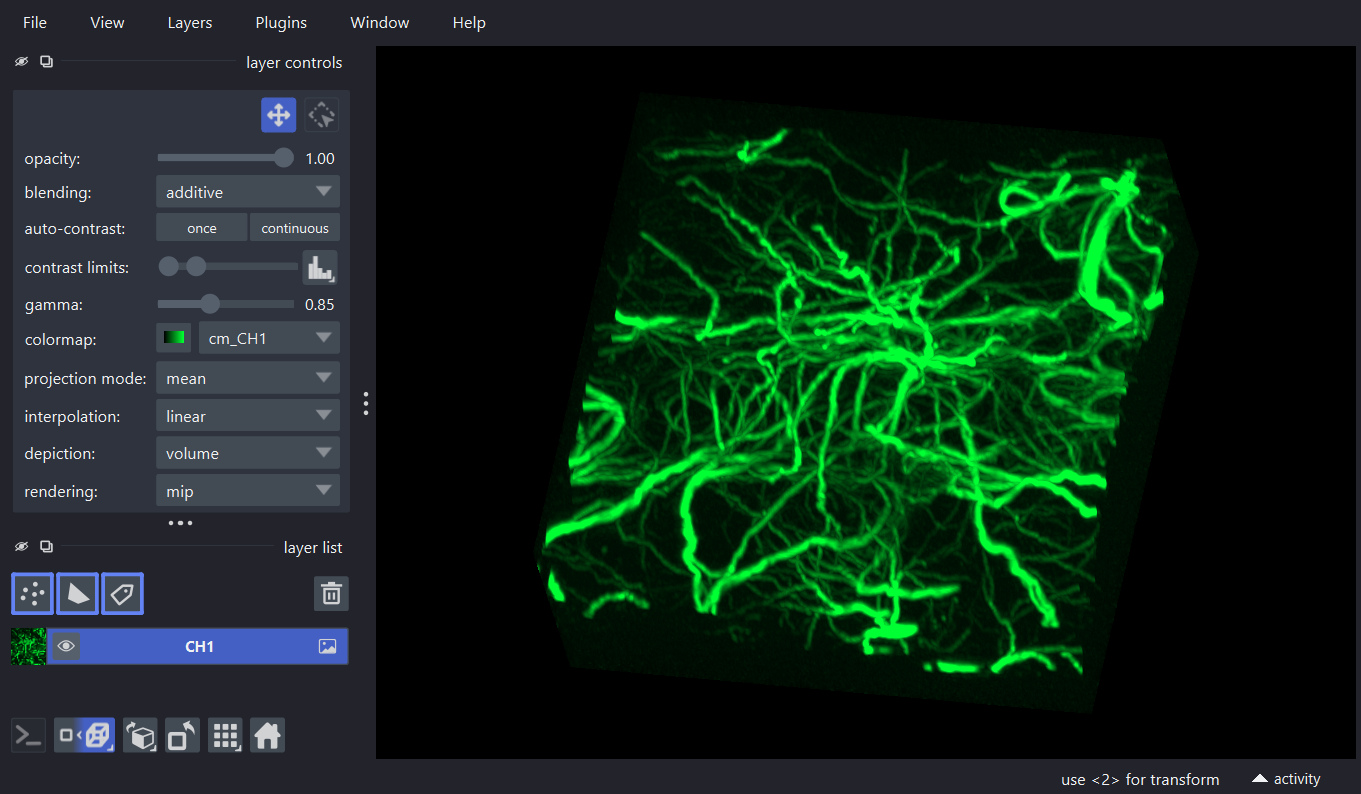

In [6]:
napari.utils.nbscreenshot(viewer)

In [10]:
result, dims, num_stacks, mdata = read_tools.read_stacks(
    filepath,
    use_dask=True,
    use_xarray=True,
    stack_scenes=True,
)

if isinstance(result, list):
    # List of per-scene arrays
    for idx, arr in enumerate(result):
        if isinstance(arr, xr.DataArray):
            print(f"Stack {idx}: dims={arr.dims}, shape={arr.shape}, dtype={arr.dtype}")
        else:
            print(f"Stack {idx}: shape={arr.shape}, dims={dims}, dtype={arr.dtype}")
else:
    # Single stacked array
    if isinstance(result, xr.DataArray):
        print(f"Stacked: dims={result.dims}, shape={result.shape}, dtype={result.dtype}")
    else:
        print(f"Stacked: shape={result.shape}, dims={dims}, dtype={result.dtype}")

    # With use_dask=True, result is backed by dask - no data loaded yet
    print(f"\nArray shape (no data loaded): {result.shape}")

# display the dask array
result[0]


  0% |                                                  | ETA:  --:--:-- 0 of 79
100% |#################################################| Time:  0:00:00 79 of 79


2026-11-12 16:43:58,273 - czitools - INFO - read_stacks: num_stacks=1 (selected from total=1), total_bounding_box={'T': (0, 1), 'Z': (0, 79), 'C': (0, 1), 'H': (0, 1), 'B': (0, 1), 'X': (0, 320), 'Y': (0, 320)}
2026-11-12 16:43:58,273 - czitools - INFO - read_stacks: canonical_dims=['H', 'T', 'C', 'Z'], dim_sizes={'H': 1, 'T': 1, 'C': 1, 'Z': 79, 'S': 1}
2026-11-12 16:43:58,273 - czitools - INFO - read_stacks: Using lazy dask arrays - data will be read on demand
2026-11-12 16:43:58,273 - czitools - INFO - read_stacks: Grouping 79 planes into tasks of at most 64 planes
2026-11-12 16:43:58,273 - czitools - INFO - read_stacks: Stacking 1 stacks (all shapes equal: (1, 1, 1, 79, 320, 320))
Stacked: dims=('S', 'H', 'T', 'C', 'Z', 'Y', 'X'), shape=(1, 1, 1, 1, 79, 320, 320), dtype=uint16

Array shape (no data loaded): (1, 1, 1, 1, 79, 320, 320)


<xarray.DataArray 'reshape-94ef93719c6b5433c296fa469f2b329f' (H: 1, T: 1, C: 1,
                                                              Z: 79, Y: 320,
                                                              X: 320)> Size: 16MB
dask.array<getitem, shape=(1, 1, 1, 79, 320, 320), dtype=uint16, chunksize=(1, 1, 1, 64, 320, 320), chunktype=numpy.ndarray>
Coordinates:
  * H        (H) int64 8B 0
  * T        (T) int64 8B 0
  * C        (C) <U3 12B 'CH1'
  * Z        (Z) float64 632B 0.0 0.27 0.54 0.81 ... 20.25 20.52 20.79 21.06
  * Y        (Y) float64 3kB 0.0 0.161 0.322 0.483 ... 50.88 51.04 51.2 51.36
  * X        (X) float64 3kB 0.0 0.161 0.322 0.483 ... 50.88 51.04 51.2 51.36
    S        int64 8B 0
Attributes:
    stack:          0
    filepath:       F:\Pixi_Projects\zen_czi\smartmicroscopy_2026-11\data\Rat...
    axes:           HTCZYX
    subset_planes:  {'S': (0, 0), 'T': (0, 0), 'C': (0, 0), 'Z': (0, 78)}

In [8]:
# If result is a list of stacks, choose display mode:
# - True: show all stacks in one viewer
# - False: show only one stack selected by ``list_stack_index``
show_all_list_stacks = True
# Stack index used when ``result`` is a list and ``show_all_list_stacks`` is False.
# Ignored when result is not a list.
list_stack_index = 0

if isinstance(result, list):
    if len(result) == 0:
        raise RuntimeError("No stack data available for Napari display.")

    if show_all_list_stacks:
        viewer = display_xarray_list_in_napari(result, mdata, run=False)
    else:
        selected_index = max(0, min(list_stack_index, len(result) - 1))
        stack = result[selected_index]
        subset_planes = stack.attrs.get("subset_planes", {}) if isinstance(stack, xr.DataArray) else {}
        print(f"Showing stack index: {selected_index}")
        viewer = display_xarray_in_napari(
            stack, mdata, subset_planes, run=False
        )
else:
    subset_planes = result.attrs.get("subset_planes", {}) if isinstance(result, xr.DataArray) else {}
    viewer = display_xarray_in_napari(
        result, mdata, subset_planes, run=False
    )